## Problem 9: Forecasting U.S. GDP Growth Using Many Macroeconomic Predictors

**Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

**Load FRED-QD Data**

In [2]:
fred_qd_url = "https://www.stlouisfed.org/-/media/project/frbstl/stlouisfed/research/fred-md/quarterly/2026-06-qd.csv"

fred_qd_raw = pd.read_csv(fred_qd_url)

fred_qd_raw.head()

,sasdate,GDPC1,PCECC96,PCDGx,PCESVx,PCNDx,GPDIC1,FPIx,Y033RC1Q027SBEAx,PNFIx,...,TNWMVBSNNCBBDIx,TLBSNNBx,TLBSNNBBDIx,TABSNNBx,TNWBSNNBx,TNWBSNNBBDIx,CNCFx,S&P 500,S&P div yield,S&P PE ratio
0,factors,0.000,0.000,1.0000,1.0000,1.0000,0.000,0.0000,1.0000,1.0000,...,0.00,0.0,0.0,0,0.00,0.00,0.0000,1.0000,0.0000,0.0000
1,transform,5.000,5.000,5.0000,5.0000,5.0000,5.000,5.0000,5.0000,5.0000,...,2.00,5.0,1.0,5,5.00,2.00,5.0000,5.0000,2.0000,5.0000
2,3/1/1959,3352.129,2039.017,68.6651,1374.1739,689.1172,354.894,357.0174,47.8021,171.0783,...,1341691.84,333239846.8,266663789.4,2426352408,2092540.86,1674484.25,124.9663,55.5167,3.1765,18.6211
3,6/1/1959,3427.667,2070.508,71.2495,1394.7096,694.8197,382.500,368.0640,49.2332,176.0004,...,1294173.52,345855787.9,273337876.4,2434980599,2088548.18,1650628.22,126.5305,57.5067,3.1012,19.2899
4,9/1/1959,3430.057,2092.138,72.6270,1413.6627,697.4699,357.798,371.9585,50.8372,180.7406,...,1320742.77,354813422.8,275143642.3,2434604027,2079200.00,1612336.58,128.9557,58.7300,3.0720,18.9544


If the URL changes, go to the St. Louis Fed FRED-MD/FRED-QD database page and download the latest FRED-QD quarterly CSV manually.

**Clean FRED-QD Data**

In [3]:
fred_qd = fred_qd_raw.copy()

fred_qd = fred_qd.rename(columns={fred_qd.columns[0]: "Date"})

fred_qd = fred_qd.iloc[1:].copy()

fred_qd["Date"] = pd.to_datetime(fred_qd["Date"], errors="coerce")

fred_qd.head()

C:\Users\sirji\AppData\Local\Temp\ipykernel_26656\153920376.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  fred_qd["Date"] = pd.to_datetime(fred_qd["Date"], errors="coerce")


,Date,GDPC1,PCECC96,PCDGx,PCESVx,PCNDx,GPDIC1,FPIx,Y033RC1Q027SBEAx,PNFIx,...,TNWMVBSNNCBBDIx,TLBSNNBx,TLBSNNBBDIx,TABSNNBx,TNWBSNNBx,TNWBSNNBBDIx,CNCFx,S&P 500,S&P div yield,S&P PE ratio
1,NaT,5.000,5.000,5.0000,5.0000,5.0000,5.000,5.0000,5.0000,5.0000,...,2.00,5.0,1.0,5,5.00,2.00,5.0000,5.0000,2.0000,5.0000
2,1959-03-01,3352.129,2039.017,68.6651,1374.1739,689.1172,354.894,357.0174,47.8021,171.0783,...,1341691.84,333239846.8,266663789.4,2426352408,2092540.86,1674484.25,124.9663,55.5167,3.1765,18.6211
3,1959-06-01,3427.667,2070.508,71.2495,1394.7096,694.8197,382.500,368.0640,49.2332,176.0004,...,1294173.52,345855787.9,273337876.4,2434980599,2088548.18,1650628.22,126.5305,57.5067,3.1012,19.2899
4,1959-09-01,3430.057,2092.138,72.6270,1413.6627,697.4699,357.798,371.9585,50.8372,180.7406,...,1320742.77,354813422.8,275143642.3,2434604027,2079200.00,1612336.58,128.9557,58.7300,3.0720,18.9544
5,1959-12-01,3439.832,2094.495,69.1573,1430.8157,701.7617,369.442,367.6452,50.7342,180.2333,...,1165668.56,349406163.1,254971696.3,2429060561,2079049.86,1517142.30,137.0372,57.7633,3.1572,17.8221


**Convert all Macro variables to numeric**

In [4]:
for col in fred_qd.columns:
    if col != "Date":
        fred_qd[col] = pd.to_numeric(fred_qd[col], errors="coerce")

fred_qd.head()

,Date,GDPC1,PCECC96,PCDGx,PCESVx,PCNDx,GPDIC1,FPIx,Y033RC1Q027SBEAx,PNFIx,...,TNWMVBSNNCBBDIx,TLBSNNBx,TLBSNNBBDIx,TABSNNBx,TNWBSNNBx,TNWBSNNBBDIx,CNCFx,S&P 500,S&P div yield,S&P PE ratio
1,NaT,5.000,5.000,5.0000,5.0000,5.0000,5.000,5.0000,5.0000,5.0000,...,2.00,5.0,1.0,5,5.00,2.00,5.0000,5.0000,2.0000,5.0000
2,1959-03-01,3352.129,2039.017,68.6651,1374.1739,689.1172,354.894,357.0174,47.8021,171.0783,...,1341691.84,333239846.8,266663789.4,2426352408,2092540.86,1674484.25,124.9663,55.5167,3.1765,18.6211
3,1959-06-01,3427.667,2070.508,71.2495,1394.7096,694.8197,382.500,368.0640,49.2332,176.0004,...,1294173.52,345855787.9,273337876.4,2434980599,2088548.18,1650628.22,126.5305,57.5067,3.1012,19.2899
4,1959-09-01,3430.057,2092.138,72.6270,1413.6627,697.4699,357.798,371.9585,50.8372,180.7406,...,1320742.77,354813422.8,275143642.3,2434604027,2079200.00,1612336.58,128.9557,58.7300,3.0720,18.9544
5,1959-12-01,3439.832,2094.495,69.1573,1430.8157,701.7617,369.442,367.6452,50.7342,180.2333,...,1165668.56,349406163.1,254971696.3,2429060561,2079049.86,1517142.30,137.0372,57.7633,3.1572,17.8221


In [5]:
fred_qd.shape

(270, 246)

**Check whether GDPC1 exists as it is the Real GDP**

In [6]:
"GDPC1" in fred_qd.columns

True

**Create GDP Growth Target**

In [7]:
fred_qd["GDP_Growth"] = np.log(fred_qd["GDPC1"]).diff() * 100

fred_qd["Next_Quarter_GDP_Growth"] = fred_qd["GDP_Growth"].shift(-1)

fred_qd[["Date", "GDPC1", "GDP_Growth", "Next_Quarter_GDP_Growth"]].head()

C:\Users\sirji\AppData\Local\Temp\ipykernel_26656\2371933353.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  fred_qd["GDP_Growth"] = np.log(fred_qd["GDPC1"]).diff() * 100
C:\Users\sirji\AppData\Local\Temp\ipykernel_26656\2371933353.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  fred_qd["Next_Quarter_GDP_Growth"] = fred_qd["GDP_Growth"].shift(-1)


,Date,GDPC1,GDP_Growth,Next_Quarter_GDP_Growth
1,NaT,5.000,NaN,650.791303
2,1959-03-01,3352.129,650.791303,2.228419
3,1959-06-01,3427.667,2.228419,0.069702
4,1959-09-01,3430.057,0.069702,0.284575
5,1959-12-01,3439.832,0.284575,2.223718


**Select Predictor Variables**

We will remove the date and GDP target columns, but keep a broad set of macro variables.

In [8]:
columns_to_exclude = [
    "Date",
    "GDPC1",
    "GDP_Growth",
    "Next_Quarter_GDP_Growth"
]

candidate_features = [
    col for col in fred_qd.columns
    if col not in columns_to_exclude
]

len(candidate_features)

244

**Removing columns that are mostly missing**

This means we keep predictors where less than 20% of the values are missing.

In [9]:
missing_share = fred_qd[candidate_features].isna().mean()

selected_features = missing_share[missing_share < 0.20].index.tolist()

len(selected_features)

230

**Create Final Modelling Dataset**

In [10]:
model_data = fred_qd[
    ["Date", "Next_Quarter_GDP_Growth"] + selected_features
].copy()

model_data = model_data.dropna(
    subset=["Date", "Next_Quarter_GDP_Growth"]
)

model_data.shape

(268, 232)

In [11]:
model_data[["Date", "Next_Quarter_GDP_Growth"]].head()

,Date,Next_Quarter_GDP_Growth
2,1959-03-01,2.228419
3,1959-06-01,0.069702
4,1959-09-01,0.284575
5,1959-12-01,2.223718
6,1960-03-01,-0.539812


**Train - Test Split**

In [12]:
train = model_data[model_data["Date"] < "2005-01-01"].copy()
test = model_data[model_data["Date"] >= "2005-01-01"].copy()

train.shape, test.shape

((184, 232), (84, 232))

**Define X and y**

In [13]:
X_train = train[selected_features]
y_train = train["Next_Quarter_GDP_Growth"]

X_test = test[selected_features]
y_test = test["Next_Quarter_GDP_Growth"]

In [14]:
X_train.shape, X_test.shape

((184, 230), (84, 230))

**Fit OLS Linear Regression**

Because we are using many predictors, we include missing-value imputation and scaling.

In [15]:
ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])

ols_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](230,)","['PCECC96','PCDGx','PCESVx',...,'S&P 500','S&P div yield','S&P PE ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,230
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data t

**Fit Ridge Regression**

In [16]:
alpha_values = np.logspace(-4, 4, 100)

time_split = TimeSeriesSplit(n_splits=5)

ridge_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=alpha_values, cv=time_split))
])

ridge_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](230,)","['PCECC96','PCDGx','PCESVx',...,'S&P 500','S&P div yield','S&P PE ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,230
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data t

**Check selected Ridge Alpha**

In [17]:
best_alpha = ridge_model.named_steps["ridge"].alpha_

best_alpha

np.float64(1873.8174228603868)

**Make Predictions**

In [18]:
ols_predictions = ols_model.predict(X_test)

ridge_predictions = ridge_model.predict(X_test)

**Compare Model Performance**

In [19]:
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))

ols_mae = mean_absolute_error(y_test, ols_predictions)
ridge_mae = mean_absolute_error(y_test, ridge_predictions)

ols_r2 = r2_score(y_test, ols_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

performance_comparison = pd.DataFrame({
    "Model": ["OLS Linear Regression", "Ridge Regression"],
    "RMSE": [ols_rmse, ridge_rmse],
    "MAE": [ols_mae, ridge_mae],
    "Test R-squared": [ols_r2, ridge_r2]
})

performance_comparison

,Model,RMSE,MAE,Test R-squared
0,OLS Linear Regression,786.226676,672.359653,-335848.416534
1,Ridge Regression,1.534399,0.935797,-0.279162


**Compare Top Coefficients**

Because there may be many predictors, we will show only the largest coefficients by absolute value.

In [20]:
ols_coefficients = ols_model.named_steps["linear"].coef_
ridge_coefficients = ridge_model.named_steps["ridge"].coef_

coefficient_comparison = pd.DataFrame({
    "Feature": selected_features,
    "OLS Coefficient": ols_coefficients,
    "Ridge Coefficient": ridge_coefficients
})

coefficient_comparison["Abs OLS Coefficient"] = coefficient_comparison["OLS Coefficient"].abs()
coefficient_comparison["Abs Ridge Coefficient"] = coefficient_comparison["Ridge Coefficient"].abs()

top_coefficients = coefficient_comparison.sort_values(
    by="Abs OLS Coefficient",
    ascending=False
).head(20)

top_coefficients

,Feature,OLS Coefficient,Ridge Coefficient,Abs OLS Coefficient,Abs Ridge Coefficient
192,CPIMEDSL,-109.665157,-0.000890,109.665157,0.000890
190,CPIAPPSL,-96.566866,-0.000332,96.566866,0.000332
2,PCESVx,87.016202,-0.000902,87.016202,0.000902
114,DOTSRG3Q086SBEA,75.583077,-0.000524,75.583077,0.000524
198,CUSR0000SA0L5,73.021371,-0.000674,73.021371,0.000674
199,CES0600000008,63.829248,-0.000649,63.829248,0.000649
122,WPSID61,-63.256527,-0.000440,63.256527,0.000440
19,INDPRO,59.620895,-0.001238,59.620895,0.001238
208,CP3M,-59.180479,-0.009637,59.180479,0.009637
104,DFXARG3Q086SBEA,-59.089378,-0.000854,59.089378,0.000854


**Plot: Top 10 OLS vs Ridge Coefficients**

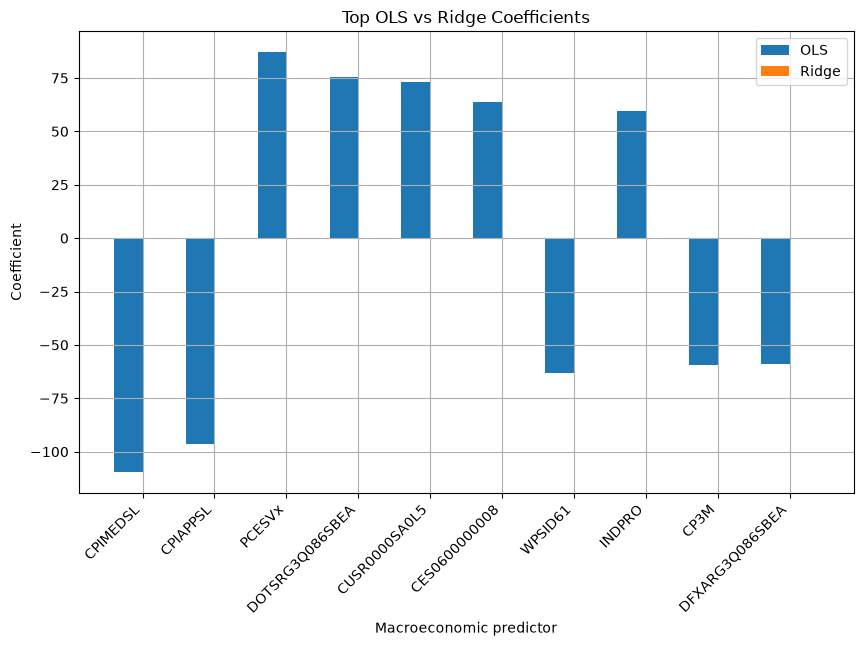

In [21]:
top_10 = coefficient_comparison.sort_values(
    by="Abs OLS Coefficient",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

x = np.arange(len(top_10))

plt.bar(
    x - 0.2,
    top_10["OLS Coefficient"],
    width=0.4,
    label="OLS"
)

plt.bar(
    x + 0.2,
    top_10["Ridge Coefficient"],
    width=0.4,
    label="Ridge"
)

plt.xticks(x, top_10["Feature"], rotation=45, ha="right")

plt.xlabel("Macroeconomic predictor")
plt.ylabel("Coefficient")
plt.title("Top OLS vs Ridge Coefficients")
plt.legend()
plt.grid(True)

plt.show()

**Actual vs Predicted GDP Growth plot**

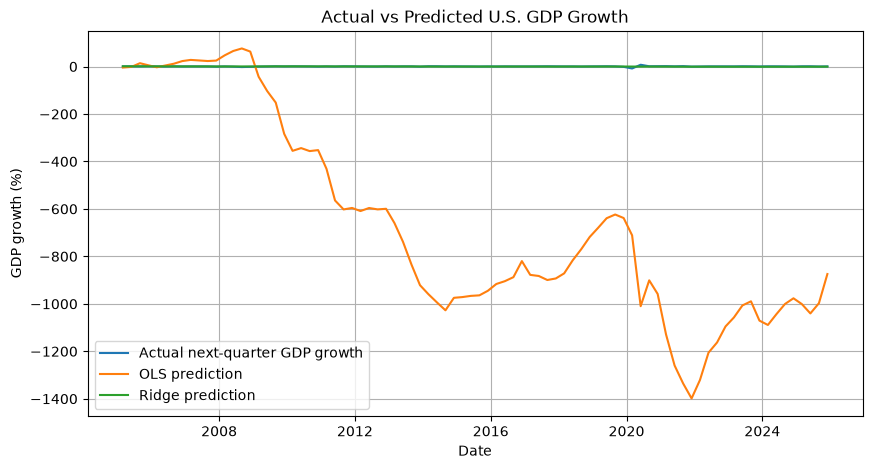

In [22]:
prediction_plot = test[["Date", "Next_Quarter_GDP_Growth"]].copy()

prediction_plot["OLS_Prediction"] = ols_predictions
prediction_plot["Ridge_Prediction"] = ridge_predictions

plt.figure(figsize=(10, 5))

plt.plot(
    prediction_plot["Date"],
    prediction_plot["Next_Quarter_GDP_Growth"],
    label="Actual next-quarter GDP growth"
)

plt.plot(
    prediction_plot["Date"],
    prediction_plot["OLS_Prediction"],
    label="OLS prediction"
)

plt.plot(
    prediction_plot["Date"],
    prediction_plot["Ridge_Prediction"],
    label="Ridge prediction"
)

plt.xlabel("Date")
plt.ylabel("GDP growth (%)")
plt.title("Actual vs Predicted U.S. GDP Growth")
plt.legend()
plt.grid(True)

plt.show()

**Residual Comparison**

In [23]:
prediction_plot["OLS_Residual"] = (
    prediction_plot["Next_Quarter_GDP_Growth"] 
    - prediction_plot["OLS_Prediction"]
)

prediction_plot["Ridge_Residual"] = (
    prediction_plot["Next_Quarter_GDP_Growth"] 
    - prediction_plot["Ridge_Prediction"]
)

residual_comparison = pd.DataFrame({
    "Model": ["OLS Linear Regression", "Ridge Regression"],
    "Residual Mean": [
        prediction_plot["OLS_Residual"].mean(),
        prediction_plot["Ridge_Residual"].mean()
    ],
    "Residual Standard Deviation": [
        prediction_plot["OLS_Residual"].std(),
        prediction_plot["Ridge_Residual"].std()
    ]
})

residual_comparison

,Model,Residual Mean,Residual Standard Deviation
0,OLS Linear Regression,662.569206,425.808550
1,Ridge Regression,0.437536,1.479528


**Simple Benchmark Model**

We should compare Ridge not only with OLS, but also with a simple benchmark. 

A common baseline is: Predict next-quarter GDP growth using the average growth rate from the training set.

This will tell us whether Ridge improves not only over OLS, but also over a very simple forecasting rule.

In [24]:
benchmark_prediction = y_train.mean()

benchmark_predictions = np.repeat(
    benchmark_prediction,
    len(y_test)
)

benchmark_rmse = np.sqrt(mean_squared_error(y_test, benchmark_predictions))
benchmark_mae = mean_absolute_error(y_test, benchmark_predictions)
benchmark_r2 = r2_score(y_test, benchmark_predictions)

benchmark_comparison = pd.DataFrame({
    "Model": [
        "Mean Benchmark",
        "OLS Linear Regression",
        "Ridge Regression"
    ],
    "RMSE": [
        benchmark_rmse,
        ols_rmse,
        ridge_rmse
    ],
    "MAE": [
        benchmark_mae,
        ols_mae,
        ridge_mae
    ],
    "Test R-squared": [
        benchmark_r2,
        ols_r2,
        ridge_r2
    ]
})

benchmark_comparison

,Model,RMSE,MAE,Test R-squared
0,Mean Benchmark,1.398856,0.640068,-0.063151
1,OLS Linear Regression,786.226676,672.359653,-335848.416534
2,Ridge Regression,1.534399,0.935797,-0.279162


## END